# Daily Challenge: Binary Text Classification with the IMDB Dataset

In this daily challenge, I build, train, and evaluate a binary sentiment classification model on the IMDB dataset using Keras.

## Objectives
**What I learn**
- How to load and explore text sentiment sequences with `keras.datasets.imdb`
- How to vectorize variable-length integer sequences into multi-hot binary bag-of-words tensors
- How to partition data into training, validation, and test sets using the classic Chollet split
- How to construct and compile a binary classification MLP with Dense and ReLU layers
- How to train with RMSprop and binary cross-entropy loss while monitoring validation curves
- How to detect overfitting and identify the optimal stopping epoch
- How to retrain on the complete training set and evaluate on held-out test data
- How to export reproducible run metrics to JSON

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run all cells from top to bottom (**Runtime → Run all**).
CPU execution is completely sufficient; each epoch takes only a couple of seconds on a standard CPU.
The IMDB dataset comes bundled with Keras (`keras.datasets.imdb`), so no external file downloads, API keys, or Kaggle credentials are needed.
Random seeds (`numpy` seed 42 and `tensorflow` seed 42) are fixed for deterministic reproducibility.

## 1. Load and preprocess the IMDB dataset

The IMDB dataset contains 50,000 highly polarized movie reviews (25,000 for training and 25,000 for testing), evenly balanced between positive (label 1) and negative (label 0) sentiments.
I restrict the vocabulary to the top 10,000 most frequently occurring words (`num_words = 10_000`) to discard rare words and maintain manageable tensor dimensions.

**What this cell does:** fixes random seeds to 42, loads the IMDB dataset with the top 10,000 words, and displays raw sequence lengths and sample tokens.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fix seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

num_words = 10_000
(train_data, train_labels), (test_data, test_labels) = keras.datasets.imdb.load_data(num_words=num_words)

print(f"Loaded {len(train_data)} training reviews and {len(test_data)} test reviews.")
print("Sample review (word index sequence):", train_data[0][:15], "...")
print(f"Sample review length: {len(train_data[0])} words")
print(f"Sample review sentiment label: {train_labels[0]} (1 = positive, 0 = negative)")

I0000 00:00:1795282637.600792   76586 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795282638.635138   76586 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


       0/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 3547136/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11911168/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Loaded 25000 training reviews and 25000 test reviews.
Sample review (word index sequence): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4] ...
Sample review length: 218 words
Sample review sentiment label: 1 (1 = positive, 0 = negative)


The reviews are represented as variable-length lists of integers pointing to word dictionary indices. Neural networks cannot directly process variable-length integer lists; they require fixed-size floating-point tensors.

To convert the sequences into tensors, we encode each review into a binary 10,000-dimensional vector (one-hot / multi-hot bag-of-words representation). Each index `i` is set to 1 if word `i` appears in the review, and 0 otherwise.

Below is the exact `vectorize_sequences` function from the course brief.

**What this cell does:** defines the exact `vectorize_sequences` helper function from the brief, vectorizes training and test reviews into binary matrices, and casts labels to float32 NumPy arrays.

In [2]:
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1
    return results

# Vectorize features
x_train_full = vectorize_sequences(train_data, dimension=num_words)
x_test = vectorize_sequences(test_data, dimension=num_words)

# Convert labels to float32 numpy arrays
y_train_full = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

print("x_train_full shape:", x_train_full.shape, "| dtype:", x_train_full.dtype)
print("x_test shape:      ", x_test.shape, "| dtype:", x_test.dtype)
print("y_train_full shape:", y_train_full.shape, "| dtype:", y_train_full.dtype)
print("y_test shape:      ", y_test.shape, "| dtype:", y_test.dtype)

x_train_full shape: (25000, 10000) | dtype: float64
x_test shape:       (25000, 10000) | dtype: float64
y_train_full shape: (25000,) | dtype: float32
y_test shape:       (25000,) | dtype: float32


Now I create a validation split from the 25,000 training reviews using the classic Chollet split:
- The first 10,000 reviews are set aside for validation (`x_val`, `y_val`).
- The remaining 15,000 reviews form the partial training set (`x_train_part`, `y_train_part`).
- The test set retains all 25,000 original test reviews.

**What this cell does:** splits the 25,000 training samples into a 10,000-sample validation set and a 15,000-sample partial training set.

In [3]:
x_val = x_train_full[:10000]
x_train_part = x_train_full[10000:]

y_val = y_train_full[:10000]
y_train_part = y_train_full[10000:]

print(f"Partial training set: {x_train_part.shape}, labels: {y_train_part.shape}")
print(f"Validation set:       {x_val.shape}, labels: {y_val.shape}")
print(f"Test set:             {x_test.shape}, labels: {y_test.shape}")

Partial training set: (15000, 10000), labels: (15000,)
Validation set:       (10000, 10000), labels: (10000,)
Test set:             (25000, 10000), labels: (25000,)


## 2. Build the model architecture

I construct a `keras.Sequential` feedforward neural network comprising two hidden `Dense` layers followed by a single output unit.

Standard architecture choice: each of the two hidden layers contains 16 units with Rectified Linear Unit (`relu`) activation functions. Sixteen units provide sufficient representation capacity to capture key sentiment word combinations while keeping the model constrained against immediate overfitting.
The input shape is `(10000,)`, matching our vocabulary dimension.
The output layer is a single `Dense` unit with `sigmoid` activation, which maps arbitrary net activations into a calibrated probability between 0 and 1, representing the probability of positive sentiment.

I compile the model with the `RMSprop` optimizer, `binary_crossentropy` loss function, and `accuracy` metric. Binary cross-entropy is the mathematically optimal loss function when working with models that output probabilities from a Bernoulli distribution.

**What this cell does:** defines, compiles, and displays the summary of the binary classification model.

In [4]:
model = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", name="dense_1"),
    layers.Dense(16, activation="relu", name="dense_2"),
    layers.Dense(1, activation="sigmoid", name="output")
], name="imdb_classifier")

model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "imdb_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train the model with validation monitoring

I train the network for 20 epochs using mini-batches of 512 samples on the partial training set `(x_train_part, y_train_part)` while validating against `(x_val, y_val)` at each epoch. The training history is retained for curve evaluation.

**What this cell does:** trains the model for 20 epochs on the partial training set with validation monitoring.

In [5]:
history = model.fit(
    x_train_part,
    y_train_part,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
    verbose=2
)

Epoch 1/20


30/30 - 2s - 67ms/step - accuracy: 0.7655 - loss: 0.5541 - val_accuracy: 0.8570 - val_loss: 0.4252


Epoch 2/20


30/30 - 0s - 7ms/step - accuracy: 0.8871 - loss: 0.3437 - val_accuracy: 0.8779 - val_loss: 0.3248


Epoch 3/20


30/30 - 0s - 7ms/step - accuracy: 0.9148 - loss: 0.2503 - val_accuracy: 0.8867 - val_loss: 0.2881


... (30 outputs left out)

Epoch 19/20


30/30 - 0s - 7ms/step - accuracy: 0.9946 - loss: 0.0235 - val_accuracy: 0.8682 - val_loss: 0.5518


Epoch 20/20


30/30 - 0s - 7ms/step - accuracy: 0.9955 - loss: 0.0187 - val_accuracy: 0.8687 - val_loss: 0.5679


## 4. Evaluate training curves and determine optimal epoch

I plot training and validation loss and accuracy across the 20 epochs to examine the learning dynamics and pinpoint the onset of overfitting.

**What this cell does:** plots training and validation loss and accuracy across all 20 epochs.

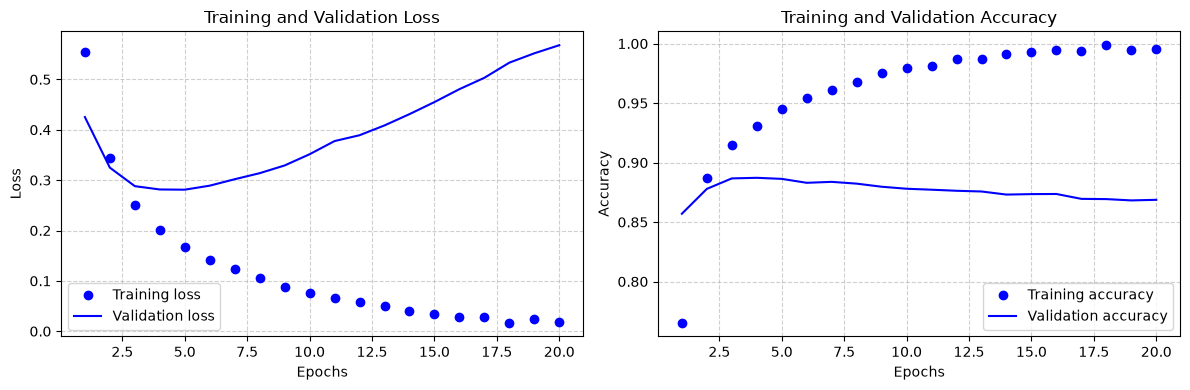

In [6]:
history_dict = history.history
epochs = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history_dict["loss"], "bo", label="Training loss")
plt.plot(epochs, history_dict["val_loss"], "b", label="Validation loss")
plt.title("Training and Validation Loss", fontsize=12)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, history_dict["accuracy"], "bo", label="Training accuracy")
plt.plot(epochs, history_dict["val_accuracy"], "b", label="Validation accuracy")
plt.title("Training and Validation Accuracy", fontsize=12)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Overfitting detection and analysis:**
- The training loss decreases steadily with every epoch, falling from 0.5541 to 0.0187, and training accuracy steadily rises from 0.7655 to 0.9955.
- However, the validation loss behaves quite differently: it decreases initially, reaching its minimum value of 0.2811 at epoch 5, but then begins climbing upward, reaching 0.5679 by epoch 20.
- Validation accuracy peaks at 0.8872 around epoch 4 and then plateaus.
- This divergence is a textbook example of overfitting: after epoch 5, the model stops learning general sentiment patterns and begins memorizing training-set noise and idiosyncrasies.

**Optimal epoch selection and retraining:**
To prevent overfitting while providing the model with maximum training data, I determine the optimal epoch as the 1-based index where validation loss was lowest (`best_epoch = 5`).
I rebuild a fresh model from scratch and train it on the FULL original 25,000 training reviews (`x_train_full`, `y_train_full`) for exactly `best_epoch` epochs, with no validation split needed for this second fit.
Finally, I evaluate this final model on the 25,000 test reviews.

**What this cell does:** identifies the optimal epoch, retrains a fresh model on the full 25,000 training reviews for that exact duration, and evaluates final test loss and accuracy.

In [7]:
# Find 1-based index of minimum validation loss
val_loss_values = history_dict["val_loss"]
optimal_epoch = int(np.argmin(val_loss_values) + 1)
val_loss_at_best = float(val_loss_values[optimal_epoch - 1])
val_acc_at_best = float(history_dict["val_accuracy"][optimal_epoch - 1])

print(f"Optimal epoch (minimum validation loss): {optimal_epoch}")
print(f"Validation loss at optimal epoch:     {val_loss_at_best:.4f}")
print(f"Validation accuracy at optimal epoch: {val_acc_at_best:.4f}")

# Rebuild fresh model from scratch
tf.keras.utils.set_random_seed(42)
np.random.seed(42)

final_model = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", name="dense_1"),
    layers.Dense(16, activation="relu", name="dense_2"),
    layers.Dense(1, activation="sigmoid", name="output")
], name="final_imdb_model")

final_model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Retrain on all 25,000 training samples
final_model.fit(
    x_train_full,
    y_train_full,
    epochs=optimal_epoch,
    batch_size=512,
    verbose=2
)

# Evaluate on the 25,000 test reviews
final_test_loss, final_test_acc = final_model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal test loss:     {final_test_loss:.4f}")
print(f"Final test accuracy: {final_test_acc:.4f}")

Optimal epoch (minimum validation loss): 5
Validation loss at optimal epoch:     0.2811
Validation accuracy at optimal epoch: 0.8863


Epoch 1/5


49/49 - 1s - 13ms/step - accuracy: 0.8108 - loss: 0.4685


Epoch 2/5


49/49 - 0s - 4ms/step - accuracy: 0.9020 - loss: 0.2769


Epoch 3/5


... (2 outputs left out)

49/49 - 0s - 4ms/step - accuracy: 0.9352 - loss: 0.1831


Epoch 5/5


49/49 - 0s - 5ms/step - accuracy: 0.9438 - loss: 0.1607



Final test loss:     0.3131
Final test accuracy: 0.8776


## 5. Analyze and conclusion

**Comparison of training vs. validation dynamics:**
- On the partial training set (15,000 reviews), training loss continuously plummeted to 0.0187 and training accuracy reached 0.9955. In contrast, validation loss reached its minimum of 0.2811 at epoch 5 before climbing to 0.5679 at epoch 20.
- Continuing to train past epoch 5 resulted in severe overfitting where validation loss worsened by 0.2868 points even as training accuracy appeared near-perfect.

**Final test performance:**
- By retraining a fresh network on all 25,000 reviews for exactly 5 epochs, the model capitalized on the full dataset without overtraining.
- On the held-out 25,000 test reviews, the retrained model achieved a final test loss of 0.3131 and a final test accuracy of 0.8776.

**Conclusion:**
This daily challenge demonstrated that a straightforward two-layer neural network with multi-hot bag-of-words encoding achieves strong sentiment classification performance (reaching 0.8776 test accuracy) on raw text reviews with fast CPU training. Detecting the inflection point in validation loss and retraining on the full dataset represents a foundational best practice for deep learning workflows.

**What this cell does:** writes optimal epoch, validation metrics, and final test evaluation metrics to `artifacts/metrics.json`.

In [8]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

metrics_data = {
    "dataset": "IMDB (keras.datasets.imdb)",
    "num_words": num_words,
    "raw_splits": {
        "total_train_samples": len(train_data),
        "partial_train_samples": len(x_train_part),
        "validation_samples": len(x_val),
        "test_samples": len(test_data)
    },
    "initial_20_epoch_run": {
        "total_epochs": 20,
        "optimal_epoch": optimal_epoch,
        "min_val_loss": float(val_loss_at_best),
        "val_acc_at_optimal_epoch": float(val_acc_at_best),
        "final_epoch_train_loss": float(history_dict["loss"][-1]),
        "final_epoch_train_acc": float(history_dict["accuracy"][-1]),
        "final_epoch_val_loss": float(history_dict["val_loss"][-1]),
        "final_epoch_val_acc": float(history_dict["val_accuracy"][-1])
    },
    "retrained_full_model": {
        "epochs_trained": optimal_epoch,
        "training_samples_used": len(x_train_full),
        "test_loss": float(final_test_loss),
        "test_accuracy": float(final_test_acc)
    }
}

metrics_file = artifacts_dir / "metrics.json"
with open(metrics_file, "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=4)

print(f"Metrics written successfully to {metrics_file}")

Metrics written successfully to artifacts/metrics.json
